# When Outliers Matter: Investigating Gradient-Based Data Selection Under Spurious Correlations

**UCLA CS 260D — Final Project | Fall 2026**

## 2. Experiment 1: Empirical Risk Minimization (ERM) Baseline

### 2.1 Introduction

This experiment establishes a baseline for binary hair-color classification on CelebA using Empirical Risk Minimization (ERM).

We use a pretrained ResNet-18 feature extractor and a lightweight classification head to predict the **Blond_Hair** attribute. The **Male** attribute serves as the spurious variable, defining four groups with substantially different representation in the training set.

Standard ERM minimizes average classification loss without explicitly accounting for group membership. Consequently, the model may achieve high average accuracy while underperforming on rare attribute combinations.

### 2.2 Experimental Objectives

1. Establish the baseline classification performance of a pretrained ResNet-18 model.
2. Measure training convergence and validation accuracy.
3. Evaluate per-group accuracy and worst-group accuracy.
4. Examine whether rare attribute combinations exhibit lower classification performance.
5. Save reproducible checkpoints and metrics for comparison with EPIC, JTT, and random filtering.

### 2.3 Research Hypothesis

We hypothesize that standard ERM may achieve relatively high overall accuracy while demonstrating lower accuracy on underrepresented attribute groups, particularly Group 3 (Blond_Hair = 1, Male = 1).

This experiment provides a baseline for evaluating whether gradient-based data selection improves or harms worst-group generalization.

### 2.4 Environment and Reproducibility

Configure PyTorch, random seeds, and Apple Silicon GPU acceleration (MPS). All experiments will use consistent settings for fair comparison.

In [1]:

# ============================================================
# 2.4 Environment setup
# ============================================================

import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

# Select hardware accelerator
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# Project paths
DATA_ROOT = Path("data/celeba")
IMAGE_DIR = DATA_ROOT / "img_align_celeba"
METADATA_PATH = Path("data/processed/celeba_metadata.csv")

# Verify dataset availability
assert IMAGE_DIR.is_dir(), "CelebA image directory not found."
assert METADATA_PATH.is_file(), "Processed metadata not found."

# Load dataset metadata
metadata = pd.read_csv(METADATA_PATH)

assert len(metadata) == 202599
assert metadata["filename"].is_unique

print("=" * 50)
print("CelebA ERM — Environment")
print("=" * 50)
print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"Device: {device}")
print(f"Random seed: {SEED}")
print(f"Total examples: {len(metadata):,}")

for split_id, name in [(0, "Train"), (1, "Validation"), (2, "Test")]:
    count = (metadata["split"] == split_id).sum()
    print(f"{name}: {count:,}")

print("\nEnvironment initialized successfully!")


CelebA ERM — Environment
PyTorch: 2.15.0
Torchvision: 0.29.2
Device: mps
Random seed: 42
Total examples: 202,599
Train: 162,770
Validation: 19,867
Test: 19,962

Environment initialized successfully!


### 2.5 Model Architecture and Preprocessing

We use an ImageNet-pretrained ResNet-18 as a frozen feature extractor, producing 512-dimensional image representations. A trainable linear classification head predicts the binary `Blond_Hair` label.

Images are resized and normalized using the pretrained model's standard preprocessing. The same feature extractor will be used across all experiments.

In [2]:

# ============================================================
# 2.5 Pretrained ResNet-18 feature extractor
# ============================================================

import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# ------------------------------------------------------------
# 1. Load ImageNet-pretrained ResNet-18
# ------------------------------------------------------------

weights = ResNet18_Weights.DEFAULT

backbone = resnet18(weights=weights)

# Replace final classification layer with identity.
# ResNet-18 now outputs 512-dimensional features.
backbone.fc = nn.Identity()

# Freeze pretrained backbone parameters.
for parameter in backbone.parameters():
    parameter.requires_grad = False

backbone = backbone.to(device)
backbone.eval()

# ------------------------------------------------------------
# 2. Define binary classification head
# ------------------------------------------------------------

classifier = nn.Linear(512, 2).to(device)

# ------------------------------------------------------------
# 3. Standard image preprocessing
# ------------------------------------------------------------

transform = weights.transforms()

# ------------------------------------------------------------
# 4. Verify model dimensions
# ------------------------------------------------------------

sample_input = torch.randn(
    1, 3, 224, 224,
    device=device
)

with torch.inference_mode():
    features = backbone(sample_input)
    output = classifier(features)

trainable_params = sum(
    p.numel()
    for p in classifier.parameters()
    if p.requires_grad
)

print("=" * 50)
print("Pretrained ResNet-18 — Architecture")
print("=" * 50)

print(f"Device: {device}")
print(f"Feature dimension: {features.shape}")
print(f"Classifier output: {output.shape}")
print(f"Trainable parameters: {trainable_params:,}")

print("\nModel initialized successfully!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/lijuntao/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 55.5MB/s]


Pretrained ResNet-18 — Architecture
Device: mps
Feature dimension: torch.Size([1, 512])
Classifier output: torch.Size([1, 2])
Trainable parameters: 1,026

Model initialized successfully!


### 2.6 Dataset and DataLoaders

Load CelebA using the official train/validation/test partitions. Each sample returns an image, binary target label, and group ID. Use consistent ImageNet preprocessing and a batch size of 64.

In [3]:

# ============================================================
# 2.6 CelebA Dataset and DataLoaders
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. Define CelebA dataset
# ------------------------------------------------------------

class CelebADataset(Dataset):
    def __init__(self, dataframe, image_dir, transform):
        self.data = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]
        image_path = self.image_dir / row["filename"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        label = int(row["label"])
        group = int(row["group"])

        return image, label, group


# ------------------------------------------------------------
# 2. Create datasets using official partitions
# ------------------------------------------------------------

train_dataset = CelebADataset(
    metadata[metadata["split"] == 0],
    IMAGE_DIR,
    transform,
)

val_dataset = CelebADataset(
    metadata[metadata["split"] == 1],
    IMAGE_DIR,
    transform,
)

test_dataset = CelebADataset(
    metadata[metadata["split"] == 2],
    IMAGE_DIR,
    transform,
)

# ------------------------------------------------------------
# 3. Configure DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 64

# num_workers=0 avoids multiprocessing issues
# in macOS Jupyter notebooks.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# ------------------------------------------------------------
# 4. Verify a sample batch
# ------------------------------------------------------------

images, labels, groups = next(iter(train_loader))

print("=" * 50)
print("CelebA DataLoader Verification")
print("=" * 50)

print(f"Batch size: {BATCH_SIZE}")
print(f"Image shape: {tuple(images.shape)}")
print(f"Label shape: {tuple(labels.shape)}")
print(f"Group shape: {tuple(groups.shape)}")

print(f"\nTraining batches: {len(train_loader):,}")
print(f"Validation batches: {len(val_loader):,}")
print(f"Test batches: {len(test_loader):,}")

print("\nDataLoaders initialized successfully!")


CelebA DataLoader Verification
Batch size: 64
Image shape: (64, 3, 224, 224)
Label shape: (64,)
Group shape: (64,)

Training batches: 2,544
Validation batches: 311
Test batches: 312

DataLoaders initialized successfully!


### 2.7 Feature Extraction Benchmark

Measure pretrained ResNet-18 throughput on Apple MPS using 10 batches. Estimate full-dataset processing time before caching the 512-dimensional features.

In [4]:

# ============================================================
# 2.7 Benchmark ResNet-18 feature extraction
# ============================================================

import time
import torch

BENCHMARK_BATCHES = 10

backbone.eval()

# Warm up the GPU with an existing batch.
with torch.inference_mode():
    _ = backbone(images.to(device))

if device.type == "mps":
    torch.mps.synchronize()
elif device.type == "cuda":
    torch.cuda.synchronize()

# ------------------------------------------------------------
# 1. Benchmark image loading + feature extraction
# ------------------------------------------------------------

start_time = time.perf_counter()
total_images = 0
feature_shape = None

with torch.inference_mode():
    for batch_idx, (batch_images, _, _) in enumerate(train_loader):

        if batch_idx >= BENCHMARK_BATCHES:
            break

        batch_images = batch_images.to(device)

        batch_features = backbone(batch_images)

        feature_shape = tuple(batch_features.shape)
        total_images += batch_images.size(0)

# Wait for GPU operations to finish before timing.
if device.type == "mps":
    torch.mps.synchronize()
elif device.type == "cuda":
    torch.cuda.synchronize()

elapsed_time = time.perf_counter() - start_time

# ------------------------------------------------------------
# 2. Calculate throughput and estimated processing time
# ------------------------------------------------------------

throughput = total_images / elapsed_time

estimated_total_seconds = len(metadata) / throughput
estimated_total_minutes = estimated_total_seconds / 60

# Float32 storage: 512 features x 4 bytes per image.
estimated_storage_mb = (
    len(metadata) * 512 * 4 / (1024 ** 2)
)

# ------------------------------------------------------------
# 3. Print benchmark results
# ------------------------------------------------------------

print("=" * 55)
print("CelebA — ResNet-18 Feature Extraction Benchmark")
print("=" * 55)

print(f"Device: {device}")
print(f"Images processed: {total_images:,}")
print(f"Elapsed time: {elapsed_time:.2f} seconds")
print(f"Throughput: {throughput:.2f} images/second")
print(f"Feature shape (last batch): {feature_shape}")

print("\nFull Dataset Estimate")
print("-" * 55)
print(f"Total images: {len(metadata):,}")
print(f"Estimated extraction: {estimated_total_minutes:.1f} minutes")
print(f"Estimated feature storage: {estimated_storage_mb:.1f} MiB")

print("\nBenchmark completed successfully!")


CelebA — ResNet-18 Feature Extraction Benchmark
Device: mps
Images processed: 640
Elapsed time: 1.04 seconds
Throughput: 617.65 images/second
Feature shape (last batch): (64, 512)

Full Dataset Estimate
-------------------------------------------------------
Total images: 202,599
Estimated extraction: 5.5 minutes
Estimated feature storage: 395.7 MiB

Benchmark completed successfully!


### 2.8 Feature Extraction and Caching

Extract frozen ResNet-18 features and save them to disk in `float32` format. Preserve dataset ordering and labels so that all subsequent experiments use identical feature representations.

In [5]:

# ============================================================
# 2.8 Extract and cache ResNet-18 features
# ============================================================

import time
import os
import numpy as np
import torch
from pathlib import Path
from numpy.lib.format import open_memmap

FEATURE_DIR = Path("data/processed/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_DIM = 512

def extract_and_cache(loader, split_name):
    """Extract features in dataset order and cache on disk."""

    feature_path = FEATURE_DIR / f"{split_name}_features.npy"
    labels_path = FEATURE_DIR / f"{split_name}_labels.npy"
    groups_path = FEATURE_DIR / f"{split_name}_groups.npy"
    temp_path = FEATURE_DIR / f"{split_name}_features.tmp.npy"

    total = len(loader.dataset)

    # Use a disk-backed array instead of storing all
    # extracted features in RAM.
    features = open_memmap(
        temp_path,
        mode="w+",
        dtype=np.float32,
        shape=(total, FEATURE_DIM),
    )

    all_labels = np.empty(total, dtype=np.int64)
    all_groups = np.empty(total, dtype=np.int64)

    backbone.eval()
    start = time.perf_counter()
    offset = 0

    try:
        with torch.inference_mode():
            for batch_idx, (images, labels, groups) in enumerate(loader):

                images = images.to(device)
                batch_features = backbone(images)

                batch_features = (
                    batch_features.cpu().numpy()
                    .astype(np.float32)
                )

                n = len(labels)
                end = offset + n

                features[offset:end] = batch_features
                all_labels[offset:end] = labels.numpy()
                all_groups[offset:end] = groups.numpy()

                offset = end

                if (batch_idx + 1) % 250 == 0:
                    print(
                        f"{split_name}: {offset:,}/{total:,} "
                        f"({offset / total:.1%})",
                        flush=True,
                    )

        assert offset == total

        # Complete writing before marking cache as ready.
        features.flush()
        del features

        os.replace(temp_path, feature_path)
        np.save(labels_path, all_labels)
        np.save(groups_path, all_groups)

    except Exception:
        del features
        temp_path.unlink(missing_ok=True)
        raise

    elapsed = time.perf_counter() - start

    print(f"\n{split_name} features saved!")
    print(f"Samples: {total:,}")
    print(f"Feature shape: ({total}, {FEATURE_DIM})")
    print(f"Extraction time: {elapsed:.1f} seconds")
    print(f"Location: {feature_path}")

# Extract training features first.
extract_and_cache(train_loader, "train")


train: 16,000/162,770 (9.8%)
train: 32,000/162,770 (19.7%)
train: 48,000/162,770 (29.5%)
train: 64,000/162,770 (39.3%)
train: 80,000/162,770 (49.1%)
train: 96,000/162,770 (59.0%)
train: 112,000/162,770 (68.8%)
train: 128,000/162,770 (78.6%)
train: 144,000/162,770 (88.5%)
train: 160,000/162,770 (98.3%)

train features saved!
Samples: 162,770
Feature shape: (162770, 512)
Extraction time: 472.7 seconds
Location: data/processed/features/train_features.npy


### 2.9 Validation and Test Feature Extraction

Extract validation and test features using the same frozen ResNet-18 and preprocessing pipeline. Save both splits separately for consistent model evaluation.

In [6]:

# ============================================================
# 2.9 Cache validation and test features
# ============================================================

# Reuse the frozen ResNet-18 feature extractor.
# Training features are already cached.

extract_and_cache(val_loader, "val")
extract_and_cache(test_loader, "test")

# ------------------------------------------------------------
# Verify cached files and dimensions
# ------------------------------------------------------------

expected_sizes = {
    "train": 162770,
    "val": 19867,
    "test": 19962,
}

print("\n" + "=" * 55)
print("CelebA Feature Cache Verification")
print("=" * 55)

for split, expected_size in expected_sizes.items():

    feature_path = FEATURE_DIR / f"{split}_features.npy"
    labels_path = FEATURE_DIR / f"{split}_labels.npy"
    groups_path = FEATURE_DIR / f"{split}_groups.npy"

    features = np.load(feature_path, mmap_mode="r")
    labels = np.load(labels_path)
    groups = np.load(groups_path)

    assert features.shape == (expected_size, 512)
    assert labels.shape == (expected_size,)
    assert groups.shape == (expected_size,)

    # Check group IDs match the saved class labels.
    assert np.all((groups // 2) == labels)

    print(
        f"{split:5s} | "
        f"Features: {features.shape} | "
        f"Labels: {labels.shape} | "
        f"Groups: {groups.shape}"
    )

print("\nAll feature caches verified successfully!")


val: 16,000/19,867 (80.5%)

val features saved!
Samples: 19,867
Feature shape: (19867, 512)
Extraction time: 51.8 seconds
Location: data/processed/features/val_features.npy
test: 16,000/19,962 (80.2%)

test features saved!
Samples: 19,962
Feature shape: (19962, 512)
Extraction time: 64.7 seconds
Location: data/processed/features/test_features.npy

CelebA Feature Cache Verification
train | Features: (162770, 512) | Labels: (162770,) | Groups: (162770,)
val   | Features: (19867, 512) | Labels: (19867,) | Groups: (19867,)
test  | Features: (19962, 512) | Labels: (19962,) | Groups: (19962,)

All feature caches verified successfully!


### 2.10 ERM Baseline Training

Train a linear classifier on frozen ResNet-18 features using cross-entropy loss and Adam. Select the best checkpoint using validation loss, without using group annotations during training.

In [7]:

# ============================================================
# 2.10 Train ERM classifier on cached CelebA features
# ============================================================

import copy
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. Load cached features and labels
# ------------------------------------------------------------

X_train = torch.from_numpy(
    np.load(FEATURE_DIR / "train_features.npy").copy()
)
y_train = torch.from_numpy(
    np.load(FEATURE_DIR / "train_labels.npy")
).long()

X_val = torch.from_numpy(
    np.load(FEATURE_DIR / "val_features.npy").copy()
)
y_val = torch.from_numpy(
    np.load(FEATURE_DIR / "val_labels.npy")
).long()

# Dataset and DataLoaders
train_feature_dataset = TensorDataset(X_train, y_train)
val_feature_dataset = TensorDataset(X_val, y_val)

train_feature_loader = DataLoader(
    train_feature_dataset,
    batch_size=512,
    shuffle=True,
)

val_feature_loader = DataLoader(
    val_feature_dataset,
    batch_size=1024,
    shuffle=False,
)

# ------------------------------------------------------------
# 2. Initialize classifier and optimizer
# ------------------------------------------------------------

torch.manual_seed(SEED)

erm_model = nn.Linear(512, 2).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    erm_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

EPOCHS = 20

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_loss = float("inf")
best_epoch = 0
best_state = None

# ------------------------------------------------------------
# 3. Training and validation
# ------------------------------------------------------------

start_time = time.perf_counter()

for epoch in range(EPOCHS):

    erm_model.train()
    total_loss = 0.0

    for features, labels in train_feature_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = erm_model(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    train_loss = total_loss / len(train_feature_dataset)

    # Validation
    erm_model.eval()

    val_loss_sum = 0.0
    correct = 0

    with torch.inference_mode():
        for features, labels in val_feature_loader:

            features = features.to(device)
            labels = labels.to(device)

            logits = erm_model(features)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * len(labels)
            correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

    val_loss = val_loss_sum / len(val_feature_dataset)
    val_acc = correct / len(val_feature_dataset) * 100

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = copy.deepcopy(erm_model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}%"
    )

# ------------------------------------------------------------
# 4. Restore best validation checkpoint
# ------------------------------------------------------------

erm_model.load_state_dict(best_state)
erm_model.eval()

elapsed = time.perf_counter() - start_time

print("\n" + "=" * 55)
print("ERM Training Summary")
print("=" * 55)

print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training time: {elapsed:.1f} seconds")
print("ERM training completed successfully!")


Epoch 01/20 | Train Loss: 0.2466 | Val Loss: 0.1891 | Val Accuracy: 92.17%
Epoch 02/20 | Train Loss: 0.1754 | Val Loss: 0.1725 | Val Accuracy: 93.11%
Epoch 03/20 | Train Loss: 0.1654 | Val Loss: 0.1679 | Val Accuracy: 93.31%
Epoch 04/20 | Train Loss: 0.1608 | Val Loss: 0.1673 | Val Accuracy: 93.45%
Epoch 05/20 | Train Loss: 0.1581 | Val Loss: 0.1601 | Val Accuracy: 93.56%
Epoch 06/20 | Train Loss: 0.1563 | Val Loss: 0.1613 | Val Accuracy: 93.61%
Epoch 07/20 | Train Loss: 0.1550 | Val Loss: 0.1583 | Val Accuracy: 93.65%
Epoch 08/20 | Train Loss: 0.1546 | Val Loss: 0.1568 | Val Accuracy: 93.78%
Epoch 09/20 | Train Loss: 0.1532 | Val Loss: 0.1559 | Val Accuracy: 93.83%
Epoch 10/20 | Train Loss: 0.1528 | Val Loss: 0.1596 | Val Accuracy: 93.71%
Epoch 11/20 | Train Loss: 0.1525 | Val Loss: 0.1547 | Val Accuracy: 93.84%
Epoch 12/20 | Train Loss: 0.1518 | Val Loss: 0.1557 | Val Accuracy: 93.81%
Epoch 13/20 | Train Loss: 0.1517 | Val Loss: 0.1579 | Val Accuracy: 93.79%
Epoch 14/20 | Train Loss:

### 2.11 ERM Training Performance

Visualize training loss, validation loss, and validation accuracy over 20 epochs to assess convergence and select the best checkpoint.

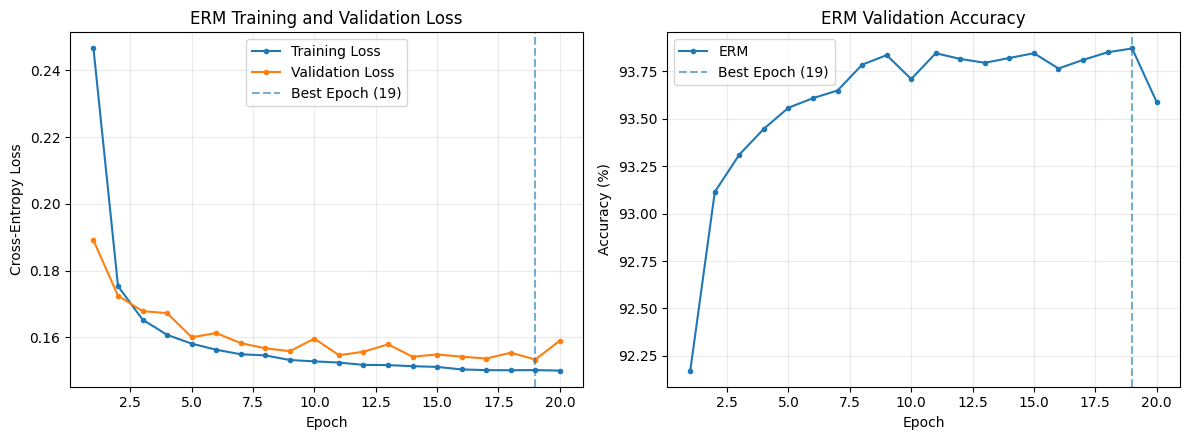

Training curves saved to: results/figures/erm_celeba_training_curves.png
Best validation epoch: 19
Best validation loss: 0.1534


In [8]:

# ============================================================
# 2.11 Visualize ERM training performance
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

epochs = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ------------------------------------------------------------
# 1. Training and validation loss
# ------------------------------------------------------------

axes[0].plot(
    epochs, history["train_loss"],
    marker="o", markersize=3,
    label="Training Loss"
)

axes[0].plot(
    epochs, history["val_loss"],
    marker="o", markersize=3,
    label="Validation Loss"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best Epoch ({best_epoch})"
)

axes[0].set_title("ERM Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

# ------------------------------------------------------------
# 2. Validation accuracy
# ------------------------------------------------------------

axes[1].plot(
    epochs, history["val_accuracy"],
    marker="o", markersize=3,
    label="ERM"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best Epoch ({best_epoch})"
)

axes[1].set_title("ERM Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure
# ------------------------------------------------------------

FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

save_path = FIGURE_DIR / "erm_celeba_training_curves.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Training curves saved to: {save_path}")
print(f"Best validation epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")


### 2.12 Group-Wise Evaluation and Robustness Analysis

Evaluate ERM on the validation set using overall accuracy, per-group accuracy, worst-group accuracy, and the accuracy gap between the best and worst groups.

This analysis determines whether high average accuracy masks poor performance on underrepresented attribute groups.

In [9]:

# ============================================================
# 2.12 ERM Group-Wise Evaluation
# ============================================================

import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Load validation features, labels, and groups
# ------------------------------------------------------------

X_val = torch.from_numpy(
    np.load(FEATURE_DIR / "val_features.npy").copy()
)

y_val = np.load(FEATURE_DIR / "val_labels.npy")
groups_val = np.load(FEATURE_DIR / "val_groups.npy")

# ------------------------------------------------------------
# 2. Generate predictions using the best ERM checkpoint
# ------------------------------------------------------------

erm_model.eval()
predictions = []

with torch.inference_mode():
    for start in range(0, len(X_val), 1024):

        batch = X_val[start:start + 1024].to(device)

        logits = erm_model(batch)
        predicted = logits.argmax(dim=1)

        predictions.append(predicted.cpu().numpy())

predictions = np.concatenate(predictions)

assert len(predictions) == len(y_val)

# ------------------------------------------------------------
# 3. Calculate overall and group-wise accuracy
# ------------------------------------------------------------

overall_accuracy = np.mean(predictions == y_val) * 100

group_names = {
    0: "Non-blond / Non-male",
    1: "Non-blond / Male",
    2: "Blond / Non-male",
    3: "Blond / Male",
}

group_results = []

for group_id in range(4):

    mask = groups_val == group_id

    group_accuracy = np.mean(
        predictions[mask] == y_val[mask]
    ) * 100

    group_results.append({
        "Group": group_id,
        "Description": group_names[group_id],
        "Samples": int(mask.sum()),
        "Accuracy (%)": group_accuracy,
    })

results_df = pd.DataFrame(group_results)

worst_group_accuracy = results_df["Accuracy (%)"].min()
best_group_accuracy = results_df["Accuracy (%)"].max()
accuracy_gap = best_group_accuracy - worst_group_accuracy

worst_group_id = int(
    results_df.loc[
        results_df["Accuracy (%)"].idxmin(), "Group"
    ]
)

# ------------------------------------------------------------
# 4. Display robustness results
# ------------------------------------------------------------

print("=" * 60)
print("ERM — CelebA Validation Robustness Analysis")
print("=" * 60)

print(f"Overall accuracy: {overall_accuracy:.2f}%")
print(f"Worst-group accuracy: {worst_group_accuracy:.2f}%")
print(f"Best-group accuracy: {best_group_accuracy:.2f}%")
print(f"Accuracy gap: {accuracy_gap:.2f} percentage points")
print(f"Worst-performing group: {worst_group_id}")

print("\nGroup-Wise Accuracy")
print("-" * 60)

print(
    results_df.to_string(
        index=False,
        formatters={
            "Accuracy (%)": "{:.2f}".format
        }
    )
)

# ------------------------------------------------------------
# 5. Save validation metrics
# ------------------------------------------------------------

METRICS_DIR = Path("results/metrics")
METRICS_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    METRICS_DIR / "erm_celeba_group_accuracy.csv",
    index=False,
)

print("\nGroup-wise metrics saved successfully!")


ERM — CelebA Validation Robustness Analysis
Overall accuracy: 93.87%
Worst-group accuracy: 17.03%
Best-group accuracy: 99.60%
Accuracy gap: 82.57 percentage points
Worst-performing group: 3

Group-Wise Accuracy
------------------------------------------------------------
 Group          Description  Samples Accuracy (%)
     0 Non-blond / Non-male     8535        94.96
     1     Non-blond / Male     8276        99.60
     2     Blond / Non-male     2874        78.98
     3         Blond / Male      182        17.03

Group-wise metrics saved successfully!


### 2.13 Group-Wise Robustness Visualization

ERM achieves 93.87% overall validation accuracy but only 17.03% accuracy on Group 3, revealing a substantial disparity across attribute groups.

This motivates our investigation of how gradient-based filtering affects minority-group performance.

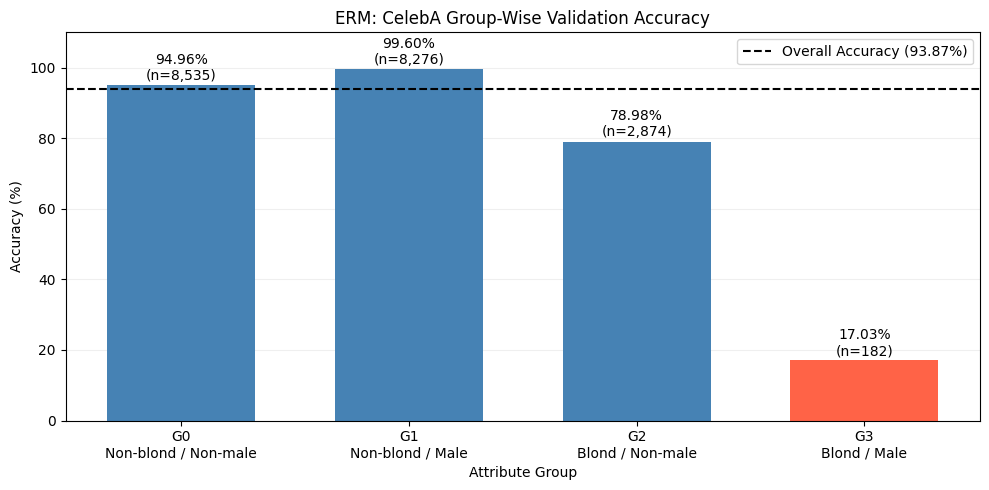

Figure saved to: results/figures/erm_celeba_group_accuracy.png
Worst-group accuracy: 17.03%
Accuracy gap: 82.57 percentage points


In [10]:

# ============================================================
# 2.13 Visualize ERM group-wise robustness
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

group_labels = [
    "G0\nNon-blond / Non-male",
    "G1\nNon-blond / Male",
    "G2\nBlond / Non-male",
    "G3\nBlond / Male",
]

accuracies = results_df["Accuracy (%)"].to_numpy()
x = np.arange(4)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    x,
    accuracies,
    color=["steelblue", "steelblue", "steelblue", "tomato"],
    width=0.65,
)

# Average accuracy reference line
ax.axhline(
    overall_accuracy,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Accuracy ({overall_accuracy:.2f}%)",
)

# Display group accuracy and sample count
for i, bar in enumerate(bars):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{accuracies[i]:.2f}%\n(n={results_df.iloc[i]['Samples']:,})",
        ha="center",
        fontsize=10,
    )

ax.set_title("ERM: CelebA Group-Wise Validation Accuracy")
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Attribute Group")
ax.set_xticks(x)
ax.set_xticklabels(group_labels)
ax.set_ylim(0, 110)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

save_path = FIGURE_DIR / "erm_celeba_group_accuracy.png"

fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")
print(f"Worst-group accuracy: {worst_group_accuracy:.2f}%")
print(f"Accuracy gap: {accuracy_gap:.2f} percentage points")


### 2.14 Save ERM Baseline Results

Save the best ERM checkpoint, training configuration, learning curves, and validation robustness metrics for reproducible comparisons with EPIC, JTT, and random filtering.

In [11]:

# ============================================================
# 2.14 Save ERM baseline experiment
# ============================================================

import json
import torch
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Create result directories
# ------------------------------------------------------------

MODEL_DIR = Path("results/models")
METRICS_DIR = Path("results/metrics")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Save best model checkpoint
# ------------------------------------------------------------

checkpoint_path = MODEL_DIR / "erm_celeba.pt"

torch.save({
    "model_state_dict": erm_model.state_dict(),
    "best_epoch": best_epoch,
    "seed": SEED,
    "input_dim": 512,
    "num_classes": 2,
    "feature_extractor": "ImageNet ResNet-18",
    "feature_extractor_frozen": True,
}, checkpoint_path)

# ------------------------------------------------------------
# 3. Save training curves
# ------------------------------------------------------------

history_df = pd.DataFrame({
    "epoch": range(1, len(history["train_loss"]) + 1),
    "train_loss": history["train_loss"],
    "val_loss": history["val_loss"],
    "val_accuracy": history["val_accuracy"],
})

history_path = METRICS_DIR / "erm_celeba_history.csv"
history_df.to_csv(history_path, index=False)

# ------------------------------------------------------------
# 4. Save experiment configuration and metrics
# ------------------------------------------------------------

experiment_results = {
    "dataset": "CelebA",
    "target": "Blond_Hair",
    "spurious_attribute": "Male",
    "architecture": "Frozen ResNet-18 + Linear Classifier",
    "feature_dimension": 512,
    "seed": SEED,
    "epochs": EPOCHS,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 512,
    "checkpoint_selection": "minimum validation loss",
    "best_epoch": int(best_epoch),
    "best_val_loss": float(best_val_loss),
    "validation": {
        "overall_accuracy": float(overall_accuracy),
        "worst_group_accuracy": float(worst_group_accuracy),
        "best_group_accuracy": float(best_group_accuracy),
        "accuracy_gap": float(accuracy_gap),
        "worst_group": int(worst_group_id),
        "group_accuracies": {
            str(int(row["Group"])): float(row["Accuracy (%)"])
            for _, row in results_df.iterrows()
        },
    },
    "training_time_seconds": float(elapsed),
}

metrics_path = METRICS_DIR / "erm_celeba.json"

with open(metrics_path, "w") as f:
    json.dump(experiment_results, f, indent=4)

# ------------------------------------------------------------
# 5. Verify saved checkpoint and results
# ------------------------------------------------------------

assert checkpoint_path.exists()
assert history_path.exists()
assert metrics_path.exists()

print("=" * 55)
print("ERM Baseline — Saved Results")
print("=" * 55)

print(f"Model: {checkpoint_path}")
print(f"Training history: {history_path}")
print(f"Metrics: {metrics_path}")

print("\nBaseline Performance")
print("-" * 55)

print(f"Best epoch: {best_epoch}")
print(f"Validation accuracy: {overall_accuracy:.2f}%")
print(f"Worst-group accuracy: {worst_group_accuracy:.2f}%")
print(f"Accuracy gap: {accuracy_gap:.2f} percentage points")

print("\nERM experiment saved successfully!")


ERM Baseline — Saved Results
Model: results/models/erm_celeba.pt
Training history: results/metrics/erm_celeba_history.csv
Metrics: results/metrics/erm_celeba.json

Baseline Performance
-------------------------------------------------------
Best epoch: 19
Validation accuracy: 93.87%
Worst-group accuracy: 17.03%
Accuracy gap: 82.57 percentage points

ERM experiment saved successfully!
